# Proyek Analisis Data: Bike Sharing Dataset

**Nama:** Filipus Satrio Dewaki Tyasing Suryo  
**Email:** ds297b6y0621@student.devacademy.id  
**ID Dicoding:** ds297b6y0621

---
Dataset: Capital Bikeshare Washington D.C. 2011–2012  
Sumber: [UCI Machine Learning Repository – Bike Sharing Dataset](https://archive.ics.uci.edu/ml/datasets/Bike+Sharing+Dataset)


## Menentukan Pertanyaan Bisnis

Berikut tiga pertanyaan bisnis terstruktur yang dirumuskan menggunakan kerangka kerja **SMART** (*Specific, Measurable, Action-Oriented, Relevant, Time-bound*). Setiap pertanyaan dirancang untuk menghasilkan wawasan kuantitatif yang langsung bermuara pada keputusan strategis dan operasional sistem *bike sharing*.

---

### Pertanyaan 1
**Bagaimana rata-rata penyewaan sepeda harian (`cnt`) pada tiap kombinasi musim dan kondisi cuaca selama 2011–2012, dan berapa persen penurunannya saat cuaca buruk dibandingkan cuaca cerah?**

| Kriteria SMART | Keterangan |
|---|---|
| **Specific** | Mengukur rata-rata penyewaan harian (`cnt`) pada kombinasi 4 musim × 3 kondisi cuaca yang tercatat pada data harian. *(Catatan: kategori cuaca 4 / Hujan Lebat hanya muncul 3 kali pada data per jam dan tidak tercatat sama sekali di data harian).* |
| **Measurable** | Dihitung secara kuantitatif melalui nilai rata-rata unit (`mean cnt`) dan persentase penurunan relatif (%) terhadap kondisi cuaca Cerah. |
| **Action-Oriented** | Menentukan kebijakan penyesuaian jumlah armada aktif di lapangan saat peringatan cuaca buruk serta menetapkan jadwal pemeliharaan preventif (*overhaul*) armada pada musim sepi. |
| **Relevant** | Membantu pengelola mengantisipasi fluktuasi permintaan drastis akibat faktor eksternal cuaca dan musim sehingga operasional tetap efisien. |
| **Time-bound** | Rentang pengamatan mencakup seluruh periode data: 1 Januari 2011 hingga 31 Desember 2012 (2 tahun penuh / 731 hari). |

---

### Pertanyaan 2
**Pada jam berapa puncak penyewaan sepeda di hari kerja dibandingkan akhir pekan/hari libur selama 2012, dan bagaimana proporsi pengguna `registered` vs `casual` pada tiap segmen waktu?**

| Kriteria SMART | Keterangan |
|---|---|
| **Specific** | Mengidentifikasi jam-jam sibuk (*peak hours*) penyewaan serta proporsi pengguna terdaftar (*registered*) vs kasual (*casual*) per segmen waktu. *(Catatan: kelompok 'Akhir Pekan/Libur' didefinisikan secara presisi sebagai `workingday == 0`, yang mencakup hari Sabtu, Minggu, dan hari libur nasional).* |
| **Measurable** | Diukur dari rata-rata penyewaan per jam (`cnt`) dan proporsi persentase (%) pengguna *registered* vs *casual* pada 5 segmen waktu harian. |
| **Action-Oriented** | Mengatur jadwal dan rute truk logistik untuk redistribusi sepeda (*bike rebalancing*) sebelum jam sibuk, serta menyusun program promosi konversi pengguna kasual menjadi member terdaftar. |
| **Relevant** | Menjaga ketersediaan dock kosong dan unit sepeda siap pakai pada lokasi-lokasi krusial agar tidak terjadi penumpukan atau kekosongan unit. |
| **Time-bound** | Difokuskan secara spesifik pada tahun 2012 (`yr == 1`), merepresentasikan kondisi sistem yang sudah mapan dan memiliki volume penyewaan tinggi. |

---

### Pertanyaan 3
**Berapa pertumbuhan total penyewaan 2012 dibanding 2011 secara bulanan (Year-over-Year per bulan), dan bulan mana yang pertumbuhannya paling rendah?**

| Kriteria SMART | Keterangan |
|---|---|
| **Specific** | Menganalisis pertumbuhan total volume penyewaan secara bulanan antar-tahun (YoY) serta mengidentifikasi 3 bulan dengan laju pertumbuhan paling lambat. |
| **Measurable** | Dihitung menggunakan metrik persentase pertumbuhan tahunan: $\frac{\text{Total 2012} - \text{Total 2011}}{\text{Total 2011}} \times 100\%$. |
| **Action-Oriented** | Menentukan bulan-bulan prioritas untuk kampanye promosi musiman dan event komunitas guna mendongkrak permintaan di periode lemah, serta merencanakan ekspansi kapasitas *docking station*. |
| **Relevant** | Memberikan visibilitas kepada pemangku kepentingan mengenai tren ekspansi bisnis, efektivitas operasional, dan kapasitas serap pasar. |
| **Time-bound** | Membandingkan 12 bulan penuh pada tahun 2011 terhadap 12 bulan penuh pada tahun 2012. |


## Import Semua Packages/Library yang Digunakan

Pada tahap ini seluruh library yang dibutuhkan diimpor. Dependensi dibatasi hanya pada pustaka inti (*pandas, numpy, matplotlib, seaborn*) untuk menjamin portabilitas dan kompatibilitas tinggi.


In [1]:
import os
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings('ignore')

# Konfigurasi gaya visualisasi global
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': '#BDC3C7',
    'axes.grid': True,
    'grid.color': '#ECF0F1',
    'grid.linestyle': '--',
    'grid.alpha': 0.7,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
})

# Palet warna konsisten
ACCENT = '#E74C3C'   # Merah: penyorot temuan utama
GRAY   = '#95A5A6'   # Abu-abu: kategori pembanding / netral
BLUE   = '#2980B9'   # Biru: kategori sekunder
DARK   = '#2C3E50'   # Biru gelap: teks dan garis batas

print("Seluruh pustaka berhasil diimpor.")
print(f"Versi pandas   : {pd.__version__}")
print(f"Versi numpy    : {np.__version__}")
print(f"Versi seaborn  : {sns.__version__}")


Seluruh pustaka berhasil diimpor.
Versi pandas   : 3.1.1
Versi numpy    : 2.5.4
Versi seaborn  : 0.13.2


## Data Wrangling

Data Wrangling terdiri dari tiga tahapan utama:
1. **Gathering Data:** Memuat berkas dataset mentah (`day.csv` dan `hour.csv`) dan memeriksa struktur dasarnya.
2. **Assessing Data:** Melakukan pemeriksaan kualitas data secara eksplisit (tipe data, nilai hilang, duplikasi, keabsahan fisik, dan outlier).
3. **Cleaning Data:** Melakukan tindakan perbaikan terukur disertai justifikasi logis untuk setiap keputusan pembersihan data.


### Gathering Data

Dataset Bike Sharing terdiri dari dua tabel:
- `day.csv`: Data agregasi harian penyewaan sepeda.
- `hour.csv`: Data penyewaan sepeda per jam.


In [2]:
# Path relatif menggunakan pathlib
data_dir = Path('data')
df_day = pd.read_csv(data_dir / 'day.csv')
df_hour = pd.read_csv(data_dir / 'hour.csv')

print(f"Dimensi df_day  : {df_day.shape[0]} baris, {df_day.shape[1]} kolom")
print(f"Dimensi df_hour : {df_hour.shape[0]} baris, {df_hour.shape[1]} kolom")


Dimensi df_day  : 731 baris, 16 kolom
Dimensi df_hour : 17379 baris, 17 kolom


In [3]:
print("=== Cuplikan 5 Baris Pertama df_day ===")
df_day.head()


=== Cuplikan 5 Baris Pertama df_day ===


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [4]:
print("=== Cuplikan 5 Baris Pertama df_hour ===")
df_hour.head()


=== Cuplikan 5 Baris Pertama df_hour ===


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [5]:
print("=== Struktur Informasi df_day ===")
df_day.info()
print("\n" + "="*50 + "\n")
print("=== Struktur Informasi df_hour ===")
df_hour.info()


=== Struktur Informasi df_day ===
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB


=== Struktur Informasi df_hour ===
<class 'pandas.DataFrame'>
RangeIndex

In [6]:
print("=== Statistik Deskriptif df_day ===")
df_day.describe().round(2)


=== Statistik Deskriptif df_day ===


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.00,731.00,731.0,731.00,731.00,731.0,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00
mean,366.00,2.50,0.5,6.52,0.03,3.0,0.68,1.40,0.50,0.47,0.63,0.19,848.18,3656.17,4504.35
std,211.17,1.11,0.5,3.45,0.17,2.0,0.47,0.54,0.18,0.16,0.14,0.08,686.62,1560.26,1937.21
min,1.00,1.00,0.0,1.00,0.00,0.0,0.00,1.00,0.06,0.08,0.00,0.02,2.00,20.00,22.00
25%,183.50,2.00,0.0,4.00,0.00,1.0,0.00,1.00,0.34,0.34,0.52,0.13,315.50,2497.00,3152.00
50%,366.00,3.00,1.0,7.00,0.00,3.0,1.00,1.00,0.50,0.49,0.63,0.18,713.00,3662.00,4548.00
75%,548.50,3.00,1.0,10.00,0.00,5.0,1.00,2.00,0.66,0.61,0.73,0.23,1096.00,4776.50,5956.00
max,731.00,4.00,1.0,12.00,1.00,6.0,1.00,3.00,0.86,0.84,0.97,0.51,3410.00,6946.00,8714.00


In [7]:
print("=== Statistik Deskriptif df_hour ===")
df_hour.describe().round(2)


=== Statistik Deskriptif df_hour ===


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.00,17379.00,17379.0,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00
mean,8690.00,2.50,0.5,6.54,11.55,0.03,3.00,0.68,1.43,0.50,0.48,0.63,0.19,35.68,153.79,189.46
std,5017.03,1.11,0.5,3.44,6.91,0.17,2.01,0.47,0.64,0.19,0.17,0.19,0.12,49.31,151.36,181.39
min,1.00,1.00,0.0,1.00,0.00,0.00,0.00,0.00,1.00,0.02,0.00,0.00,0.00,0.00,0.00,1.00
25%,4345.50,2.00,0.0,4.00,6.00,0.00,1.00,0.00,1.00,0.34,0.33,0.48,0.10,4.00,34.00,40.00
50%,8690.00,3.00,1.0,7.00,12.00,0.00,3.00,1.00,1.00,0.50,0.48,0.63,0.19,17.00,115.00,142.00
75%,13034.50,3.00,1.0,10.00,18.00,0.00,5.00,1.00,2.00,0.66,0.62,0.78,0.25,48.00,220.00,281.00
max,17379.00,4.00,1.0,12.00,23.00,1.00,6.00,1.00,4.00,1.00,1.00,1.00,0.85,367.00,886.00,977.00


> **Insight Gathering Data:**
> - Dataset harian (`day.csv`) memuat **731 baris** yang mencakup seluruh rentang waktu 2 tahun penuh (1 Januari 2011 hingga 31 Desember 2012) tanpa ada tanggal yang terlewat ($365 + 366 = 731$ hari pada tahun kabisat 2012).
> - Dataset per jam (`hour.csv`) memuat **17.379 baris**. Terdapat selisih 165 baris dari total jam teoretis ($731 \times 24 = 17.544$ jam), yang menunjukkan adanya jam-jam tertentu yang tidak tercatat.
> - Nilai variabel lingkungan (`temp`, `atemp`, `hum`, `windspeed`) tersimpan dalam format ternormalisasi (skala 0–1), sehingga perlu dikembalikan ke satuan aslinya agar dapat dipahami dan diinterpretasikan secara kontekstual.


### Assessing Data

Pada tahap ini dilakukan pemeriksaan kualitas data secara sistematis melalui kode eksplisit untuk mengidentifikasi *missing values*, duplikasi, ketidaksesuaian tipe data, anomali nilai fisik, dan outlier.


In [8]:
# Pemeriksaan Missing Value & Duplikasi
print("=== Pemeriksaan Nilai Hilang (NaN / Null) ===")
print("df_day  missing values:\n", df_day.isna().sum())
print("\ndf_hour missing values:\n", df_hour.isna().sum())

print("\n=== Pemeriksaan Duplikasi Baris ===")
print(f"Duplikasi df_day  : {df_day.duplicated().sum()} baris")
print(f"Duplikasi df_hour : {df_hour.duplicated().sum()} baris")


=== Pemeriksaan Nilai Hilang (NaN / Null) ===
df_day  missing values:
 instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

df_hour missing values:
 instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

=== Pemeriksaan Duplikasi Baris ===
Duplikasi df_day  : 0 baris


Duplikasi df_hour : 0 baris


In [9]:
# Pemeriksaan Tipe Data Kolom
print("=== Tipe Data Kolom df_day ===")
print(df_day.dtypes)
print("\n=== Tipe Data Kolom df_hour ===")
print(df_hour.dtypes)


=== Tipe Data Kolom df_day ===
instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

=== Tipe Data Kolom df_hour ===
instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object


#### Identifikasi Masalah Kualitas Data (Tabel Steps to Take)

Berdasarkan pemeriksaan awal, berikut 7 isu kualitas data yang ditemukan beserta langkah penanganan dan justifikasinya:

| # | Masalah | Tipe Isu | Dataset | Steps to Take (Tindakan) | Alasan / Justifikasi |
|---|---|---|---|---|---|
| **a** | `dteday` bertipe `object` | Inaccurate data type | `day.csv`, `hour.csv` | Konversi ke tipe `datetime64[ns]` | Memungkinkan operasi pemfilteran waktu dan ekstraksi fitur berbasis deret waktu. |
| **b** | Kolom kategorikal (`season`, `yr`, `mnth`, `weekday`, `weathersit`) berupa kode angka | Uninformative values | `day.csv`, `hour.csv` | Lakukan mapping ke label deskriptif berbahasa manusia | Mempermudah interpretasi analisis, pelabelan visualisasi, dan keterbacaan laporan. |
| **c** | Nilai kelembapan `hum == 0` | Invalid physical value | `day.csv`, `hour.csv` | Imputasi menggunakan nilai median `hum` per musim | Kelembapan 0% di alam terbuka Washington D.C. tidak valid secara fisik; median per musim mencerminkan iklim alami tanpa distorsi outlier. |
| **d** | Nilai `windspeed == 0` dalam jumlah masif di `hour.csv` (2.180 baris) | Missing recorded as zero | `hour.csv` | Imputasi nilai 0 dengan median kecepatan angin per musim | Kecepatan angin 0 km/jam secara berkepanjangan terindikasi sebagai batas ambang sensor (*calm sensor limit*); imputasi per musim mengembalikan distribusi wajar. |
| **e** | Terdapat outlier pada penyewaan (`cnt`) di `hour.csv` | Statistical outliers | `hour.csv` | Beri penanda (*flag*) boolean `cnt_outlier` tanpa membuang baris | Lonjakan penyewaan di jam sibuk komuter adalah permintaan nyata, bukan kesalahan entri data; membuangnya akan menghilangkan fenomena bisnis utama. |
| **f** | Selisih 165 jam hilang di `hour.csv` ($17.544 - 17.379$) dan `weathersit == 4` hanya 3 baris | Missing time records & severe imbalance | `hour.csv` | Dokumentasikan secara transparan tanpa melakukan imputasi baris sintetis | Menciptakan 165 baris buatan berisiko memperkenalkan data artifisial; agregasi rata-rata per jam tidak terganggu oleh jam yang absen. |
| **g** | Fitur cuaca (`temp`, `atemp`, `hum`, `windspeed`) masih ternormalisasi | Normalized values | `day.csv`, `hour.csv` | Kalikan dengan faktor skala asli masing-masing | Memberikan interpretasi langsung dalam satuan internasional (°C, %, km/jam). |


In [10]:
# (a) Verifikasi dteday object
print("=== (a) Tipe Data dteday ===")
print("day['dteday']  :", df_day['dteday'].dtype)
print("hour['dteday'] :", df_hour['dteday'].dtype)

# (b) Verifikasi nilai unik kode numerik
print("\n=== (b) Nilai Unik Fitur Kategorikal (df_day) ===")
for col in ['season', 'yr', 'mnth', 'weekday', 'weathersit']:
    print(f"Kolom {col:<11} : {sorted(df_day[col].unique())}")

# (c) Verifikasi kelembapan 0
hum0_day = (df_day['hum'] == 0).sum()
hum0_hour = (df_hour['hum'] == 0).sum()
print(f"\n=== (c) Jumlah Baris hum == 0 ===")
print(f"df_day  : {hum0_day} baris")
print(f"df_hour : {hum0_hour} baris (tanggal: {df_hour[df_hour['hum']==0]['dteday'].unique()})")

# (d) Verifikasi windspeed 0 di hour.csv
ws0_day = (df_day['windspeed'] == 0).sum()
ws0_hour = (df_hour['windspeed'] == 0).sum()
print(f"\n=== (d) Jumlah Baris windspeed == 0 ===")
print(f"df_day  : {ws0_day} baris")
print(f"df_hour : {ws0_hour} baris ({ws0_hour / len(df_hour) * 100:.2f}% dari seluruh data jam)")

# (e) Identifikasi Outlier cnt via IQR
print("\n=== (e) Identifikasi Outlier cnt Menggunakan IQR ===")
for name, df in [('df_day', df_day), ('df_hour', df_hour)]:
    q1 = df['cnt'].quantile(0.25)
    q3 = df['cnt'].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = ((df['cnt'] < lower) | (df['cnt'] > upper)).sum()
    print(f"{name:<8} : Q1={q1:.1f}, Q3={q3:.1f}, IQR={iqr:.1f}, Batas Atas={upper:.1f} -> Outlier: {outliers} baris ({outliers/len(df)*100:.2f}%)")

# (f) Verifikasi jam hilang dan weathersit == 4
total_teoretis = 731 * 24
selisih_jam = total_teoretis - len(df_hour)
w4_day = (df_day['weathersit'] == 4).sum()
w4_hour = (df_hour['weathersit'] == 4).sum()
print(f"\n=== (f) Jam Hilang dan weathersit == 4 ===")
print(f"Jam teoretis (731 x 24) : {total_teoretis}")
print(f"Jam aktual di df_hour   : {len(df_hour)} -> Hilang: {selisih_jam} jam")
print(f"weathersit == 4 di day  : {w4_day} baris (tidak pernah muncul)")
print(f"weathersit == 4 di hour : {w4_hour} baris (kondisi ekstrem sangat langka)")

# (g) Verifikasi rentang fitur ternormalisasi
print("\n=== (g) Rentang Nilai Fitur Cuaca Ternormalisasi ===")
print(df_day[['temp', 'atemp', 'hum', 'windspeed']].describe().loc[['min', 'max']].round(4))


=== (a) Tipe Data dteday ===
day['dteday']  : str
hour['dteday'] : str

=== (b) Nilai Unik Fitur Kategorikal (df_day) ===
Kolom season      : [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Kolom yr          : [np.int64(0), np.int64(1)]
Kolom mnth        : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
Kolom weekday     : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Kolom weathersit  : [np.int64(1), np.int64(2), np.int64(3)]

=== (c) Jumlah Baris hum == 0 ===
df_day  : 1 baris


df_hour : 22 baris (tanggal: <ArrowStringArray>
['2011-03-10']
Length: 1, dtype: str)

=== (d) Jumlah Baris windspeed == 0 ===
df_day  : 0 baris
df_hour : 2180 baris (12.54% dari seluruh data jam)

=== (e) Identifikasi Outlier cnt Menggunakan IQR ===
df_day   : Q1=3152.0, Q3=5956.0, IQR=2804.0, Batas Atas=10162.0 -> Outlier: 0 baris (0.00%)
df_hour  : Q1=40.0, Q3=281.0, IQR=241.0, Batas Atas=642.5 -> Outlier: 505 baris (2.91%)

=== (f) Jam Hilang dan weathersit == 4 ===
Jam teoretis (731 x 24) : 17544
Jam aktual di df_hour   : 17379 -> Hilang: 165 jam
weathersit == 4 di day  : 0 baris (tidak pernah muncul)
weathersit == 4 di hour : 3 baris (kondisi ekstrem sangat langka)

=== (g) Rentang Nilai Fitur Cuaca Ternormalisasi ===
       temp   atemp     hum  windspeed
min  0.0591  0.0791  0.0000     0.0224
max  0.8617  0.8409  0.9725     0.5075


> **Insight Assessing Data:**
> - Tidak ditemukan *missing value* eksplisit (NaN) maupun baris duplikat pada kedua dataset.
> - Namun, ditemukan 7 masalah kualitas data substantif:
>   1. Kolom `dteday` bertipe `object` sehingga belum siap untuk manipulasi time-series.
>   2. Seluruh variabel kategorikal (`season`, `yr`, `mnth`, `weekday`, `weathersit`) berupa angka arbitrer yang tidak informatif.
>   3. Terdapat nilai fisik tidak valid `hum == 0` sebanyak 1 baris di `day.csv` dan 22 baris di `hour.csv` (terjadi pada 10 Maret 2011).
>   4. Terdapat 2.180 baris `windspeed == 0` pada `hour.csv` (12,54% dari seluruh observasi jam) yang mengindikasikan sensor anemometer gagal mencatat atau berada di bawah *starting threshold*.
>   5. Terdapat 505 outlier pada variabel `cnt` di `hour.csv` (2,91%), yang terbukti terjadi pada jam sibuk komuter (jam 17.00–18.00) dan bukan merupakan galat entri.
>   6. Terdapat 165 jam yang absen di `hour.csv` dibanding total teoretis (17.544 jam), serta kondisi cuaca 4 (*Heavy Rain/Snow*) hanya terjadi 3 kali di `hour.csv` dan 0 kali di `day.csv`.
>   7. Variabel suhu, kelembapan, dan kecepatan angin berada dalam skala normalisasi (0–1).


### Cleaning Data

Berdasarkan rencana penanganan pada tahap Assessing, dilakukan langkah pembersihan data sebagai berikut:
- **6 masalah diselesaikan melalui kode transformasi data:** (a) konversi tipe data datetime, (b) mapping label deskriptif, (g) denormalisasi ke satuan internasional, (c) imputasi `hum == 0` dengan median musiman, (d) imputasi `windspeed == 0` dengan median musiman, dan (e) penandaan boolean outlier `cnt`.
- **1 masalah didokumentasikan tanpa imputasi:** Masalah (f) mengenai 165 jam yang hilang di `hour.csv` tidak diimputasi dengan baris buatan, dengan justifikasi kuat bahwa sintesis data jam secara artifisial berisiko merusak integritas data riil, sementara seluruh analisis berbasis jam menggunakan metrik rata-rata (`mean()`) yang secara matematis tidak terdistorsi oleh jam yang absen.


In [11]:
# Salin dataframe mentah
df_day_clean = df_day.copy()
df_hour_clean = df_hour.copy()

# ── (a) Konversi dteday ke Datetime ───────────────────────────────────────────
df_day_clean['dteday'] = pd.to_datetime(df_day_clean['dteday'])
df_hour_clean['dteday'] = pd.to_datetime(df_hour_clean['dteday'])
print("(a) dteday berhasil dikonversi ke datetime64[ns] ✓")

# ── (b) Mapping Label Deskriptif ──────────────────────────────────────────────
season_map = {1: 'Semi', 2: 'Panas', 3: 'Gugur', 4: 'Dingin'}
yr_map = {0: 2011, 1: 2012}
mnth_map = {
    1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'Mei', 6: 'Jun',
    7: 'Jul', 8: 'Agu', 9: 'Sep', 10: 'Okt', 11: 'Nov', 12: 'Des'
}
weekday_map = {
    0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu',
    4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'
}
weather_map = {
    1: 'Cerah',
    2: 'Berkabut/Mendung',
    3: 'Hujan/Salju Ringan',
    4: 'Hujan Lebat'
}

for df in [df_day_clean, df_hour_clean]:
    df['season_label']  = df['season'].map(season_map)
    df['yr_label']      = df['yr'].map(yr_map)
    df['mnth_label']    = df['mnth'].map(mnth_map)
    df['weekday_label'] = df['weekday'].map(weekday_map)
    df['weather_label'] = df['weathersit'].map(weather_map)

print("(b) Pemetaan label deskriptif selesai ✓")

# ── (g) Denormalisasi Fitur Cuaca ke Satuan Asli ──────────────────────────────
# Berdasarkan Readme.txt resmi UCI:
# temp dikalikan 41 (°C), atemp dikalikan 50 (°C), hum dikalikan 100 (%), windspeed dikalikan 67 (km/jam)
for df in [df_day_clean, df_hour_clean]:
    df['temp_c']        = (df['temp'] * 41).round(2)
    df['atemp_c']       = (df['atemp'] * 50).round(2)
    df['hum_pct']       = (df['hum'] * 100).round(2)
    df['windspeed_kmh'] = (df['windspeed'] * 67).round(2)

print("(g) Denormalisasi fitur cuaca selesai ✓")

# ── (c) Imputasi hum == 0 dengan Median Musiman ───────────────────────────────
def impute_zero_with_season_median(df, col, clean_col):
    mask = df[col] == 0
    n_zeros = mask.sum()
    if n_zeros > 0:
        medians = df[df[col] > 0].groupby('season')[col].median()
        df.loc[mask, col] = df.loc[mask, 'season'].map(medians)
        df[clean_col] = (df[col] * 100).round(2)
    return n_zeros

n_hum_day = impute_zero_with_season_median(df_day_clean, 'hum', 'hum_pct')
n_hum_hour = impute_zero_with_season_median(df_hour_clean, 'hum', 'hum_pct')
print(f"(c) Imputasi hum == 0: {n_hum_day} baris di day.csv, {n_hum_hour} baris di hour.csv ✓")

# ── (d) Imputasi windspeed == 0 di hour.csv dengan Median Musiman ─────────────
mask_ws = df_hour_clean['windspeed'] == 0
n_ws = mask_ws.sum()
ws_medians = df_hour_clean[df_hour_clean['windspeed'] > 0].groupby('season')['windspeed'].median()
df_hour_clean.loc[mask_ws, 'windspeed'] = df_hour_clean.loc[mask_ws, 'season'].map(ws_medians)
df_hour_clean['windspeed_kmh'] = (df_hour_clean['windspeed'] * 67).round(2)
print(f"(d) Imputasi windspeed == 0: {n_ws} baris di hour.csv berhasil diimputasi dengan median musiman ✓")

# ── (e) Penandaan Outlier cnt Menggunakan Flag Boolean IQR ─────────────────────
for name, df in [('day', df_day_clean), ('hour', df_hour_clean)]:
    q1 = df['cnt'].quantile(0.25)
    q3 = df['cnt'].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    df['cnt_outlier'] = ((df['cnt'] < lower) | (df['cnt'] > upper))
    print(f"(e) Flag outlier cnt pada {name:<4}: {df['cnt_outlier'].sum()} baris ditandai (tidak dihapus) ✓")


(a) dteday berhasil dikonversi ke datetime64[ns] ✓


(b) Pemetaan label deskriptif selesai ✓
(g) Denormalisasi fitur cuaca selesai ✓
(c) Imputasi hum == 0: 1 baris di day.csv, 22 baris di hour.csv ✓
(d) Imputasi windspeed == 0: 2180 baris di hour.csv berhasil diimputasi dengan median musiman ✓
(e) Flag outlier cnt pada day : 0 baris ditandai (tidak dihapus) ✓
(e) Flag outlier cnt pada hour: 505 baris ditandai (tidak dihapus) ✓


In [12]:
# ── Verifikasi Before vs After dalam Tabel Ringkas ────────────────────────────
verifikasi_data = [
    {
        'Parameter': 'Tipe Data dteday',
        'Dataset': 'day.csv & hour.csv',
        'Sebelum Cleaning': 'object (string)',
        'Setelah Cleaning': str(df_day_clean['dteday'].dtype),
        'Status': 'Selesai'
    },
    {
        'Parameter': 'Jumlah hum == 0',
        'Dataset': 'day.csv',
        'Sebelum Cleaning': '1 baris',
        'Setelah Cleaning': f"{(df_day_clean['hum'] == 0).sum()} baris",
        'Status': 'Terimputasi'
    },
    {
        'Parameter': 'Jumlah hum == 0',
        'Dataset': 'hour.csv',
        'Sebelum Cleaning': '22 baris',
        'Setelah Cleaning': f"{(df_hour_clean['hum'] == 0).sum()} baris",
        'Status': 'Terimputasi'
    },
    {
        'Parameter': 'Jumlah windspeed == 0',
        'Dataset': 'hour.csv',
        'Sebelum Cleaning': '2.180 baris (12,54%)',
        'Setelah Cleaning': f"{(df_hour_clean['windspeed'] == 0).sum()} baris (0%)",
        'Status': 'Terimputasi'
    },
    {
        'Parameter': 'Rentang temp_c (°C)',
        'Dataset': 'day.csv',
        'Sebelum Cleaning': f"{df_day['temp'].min():.2f} - {df_day['temp'].max():.2f} (norm)",
        'Setelah Cleaning': f"{df_day_clean['temp_c'].min():.2f}°C - {df_day_clean['temp_c'].max():.2f}°C",
        'Status': 'Tedenormalisasi'
    },
    {
        'Parameter': 'Penanganan Outlier cnt',
        'Dataset': 'hour.csv',
        'Sebelum Cleaning': '505 nilai ekstrem',
        'Setelah Cleaning': '505 baris berlabel boolean (dipertahankan)',
        'Status': 'Ditandai'
    },
    {
        'Parameter': 'Total Kolom',
        'Dataset': 'day.csv / hour.csv',
        'Sebelum Cleaning': f"{df_day.shape[1]} / {df_hour.shape[1]} kolom",
        'Setelah Cleaning': f"{df_day_clean.shape[1]} / {df_hour_clean.shape[1]} kolom",
        'Status': '+10 Kolom Baru'
    }
]

df_verifikasi = pd.DataFrame(verifikasi_data)
print("=== TABEL VERIFIKASI SEBELUM VS SESUDAH CLEANING ===")
df_verifikasi


=== TABEL VERIFIKASI SEBELUM VS SESUDAH CLEANING ===


,Parameter,Dataset,Sebelum Cleaning,Setelah Cleaning,Status
0,Tipe Data dteday,day.csv & hour.csv,object (string),datetime64[us],Selesai
1,Jumlah hum == 0,day.csv,1 baris,0 baris,Terimputasi
2,Jumlah hum == 0,hour.csv,22 baris,0 baris,Terimputasi
3,Jumlah windspeed == 0,hour.csv,"2.180 baris (12,54%)",0 baris (0%),Terimputasi
4,Rentang temp_c (°C),day.csv,0.06 - 0.86 (norm),2.42°C - 35.33°C,Tedenormalisasi
5,Penanganan Outlier cnt,hour.csv,505 nilai ekstrem,505 baris berlabel boolean (dipertahankan),Ditandai
6,Total Kolom,day.csv / hour.csv,16 / 17 kolom,26 / 27 kolom,+10 Kolom Baru


In [13]:
# ── Penyimpanan Data Bersih untuk Dashboard ───────────────────────────────────
dashboard_dir = Path('dashboard')
dashboard_dir.mkdir(parents=True, exist_ok=True)

df_day_clean.to_csv(dashboard_dir / 'main_data.csv', index=False)
df_hour_clean.to_csv(dashboard_dir / 'main_hour_data.csv', index=False)

print("Data bersih berhasil disimpan:")
print(f"  → {dashboard_dir / 'main_data.csv'} ({df_day_clean.shape[0]} baris, {df_day_clean.shape[1]} kolom)")
print(f"  → {dashboard_dir / 'main_hour_data.csv'} ({df_hour_clean.shape[0]} baris, {df_hour_clean.shape[1]} kolom)")


Data bersih berhasil disimpan:
  → dashboard/main_data.csv (731 baris, 26 kolom)
  → dashboard/main_hour_data.csv (17379 baris, 27 kolom)


> **Insight Cleaning Data:**
> - Dari 7 masalah yang ditemukan, **6 masalah kualitas data berhasil ditangani melalui transformasi kode**: konversi tipe data ke datetime, penambahan label informatif, denormalisasi satuan, imputasi median musiman untuk kelembapan nol dan kecepatan angin nol, serta penandaan boolean IQR pada nilai ekstrem `cnt`.
> - Masalah ke-7 (165 jam yang hilang pada `hour.csv`) secara sadar **didokumentasikan tanpa imputasi baris sintetis**, karena pembuatan data jam artifisial dapat menciptakan bias palsu pada pola perilaku harian, sedangkan metode analisis kita yang berbasis rata-rata jam (`groupby('hr').mean()`) kebal terhadap dampak jam yang tidak tercatat.
> - Data bersih telah disimpan ke folder `dashboard/` dan siap digunakan untuk eksplorasi dan visualisasi interaktif.


## Exploratory Data Analysis (EDA)

Pada tahapan EDA, dilakukan penjelajahan mendalam melalui statistik deskriptif, analisis korelasi, pengelompokan (*groupby*), dan tabulasi silang (*pivot table*) untuk menjawab masing-masing pertanyaan bisnis.


### Eksplorasi Lanjutan: Analisis Korelasi & Karakteristik Tipe Hari

Sebelum mendalami tiap pertanyaan spesifik, dilakukan analisis korelasi numerik untuk memahami faktor iklim yang paling memengaruhi volume penyewaan, serta perbandingan perilaku pengguna pada hari kerja vs hari libur.


In [14]:
# Analisis Korelasi Fitur Cuaca dengan cnt
corr_features = ['cnt', 'temp_c', 'atemp_c', 'hum_pct', 'windspeed_kmh']
corr_matrix = df_day_clean[corr_features].corr().round(3)

print("=== Matriks Korelasi dengan Volume Penyewaan (cnt) ===")
print(corr_matrix['cnt'])


=== Matriks Korelasi dengan Volume Penyewaan (cnt) ===
cnt              1.000
temp_c           0.627
atemp_c          0.631
hum_pct         -0.113
windspeed_kmh   -0.235
Name: cnt, dtype: float64


In [15]:
# Perbandingan Perilaku Pengguna: Hari Kerja (workingday=1) vs Akhir Pekan/Libur (workingday=0)
workingday_summary = df_day_clean.groupby('workingday').agg(
    jumlah_hari     = ('cnt', 'count'),
    total_penyewaan = ('cnt', 'sum'),
    rata_total      = ('cnt', 'mean'),
    rata_registered = ('registered', 'mean'),
    rata_casual     = ('casual', 'mean'),
    proporsi_casual = ('casual', lambda x: (x.sum() / df_day_clean.loc[x.index, 'cnt'].sum() * 100))
).round(2)

workingday_summary.index = ['Akhir Pekan / Hari Libur (0)', 'Hari Kerja (1)']
print("=== Karakteristik Penyewaan Berdasarkan Tipe Hari ===")
workingday_summary


=== Karakteristik Penyewaan Berdasarkan Tipe Hari ===


,jumlah_hari,total_penyewaan,rata_total,rata_registered,rata_casual,proporsi_casual
Akhir Pekan / Hari Libur (0),231,1000269,4330.17,2959.03,1371.13,31.66
Hari Kerja (1),500,2292410,4584.82,3978.25,606.57,13.23


> **Insight EDA Karakteristik Umum:**
> - **Suhu adalah faktor pendorong utama:** Suhu (`temp_c`, $r = +0.627$) dan suhu semu (`atemp_c`, $r = +0.631$) memiliki korelasi positif yang sangat kuat dengan jumlah penyewaan. Sebaliknya, kecepatan angin ($r = -0.235$) dan kelembapan ($r = -0.113$) berkorelasi negatif.
> - **Perbedaan perilaku pada Hari Kerja vs Hari Libur:** Rata-rata penyewaan harian pada hari kerja (4.584,8 unit/hari) sedikit lebih tinggi dibanding akhir pekan/libur (4.330,2 unit/hari). Namun, komposisi penggunanya sangat berbeda: pada akhir pekan/libur, rata-rata pengguna kasual melonjak lebih dari 2 kali lipat menjadi **1.371,1 unit/hari** (proporsi 31,67%) dibandingkan hari kerja yang hanya **606,6 unit/hari** (proporsi 13,23%).


### EDA – Pertanyaan 1: Rata-Rata Penyewaan per Kombinasi Musim & Cuaca

Bagian ini mengeksplorasi bagaimana kombinasi 4 musim dan 3 kondisi cuaca memengaruhi rata-rata penyewaan sepeda harian (`cnt`).


In [16]:
# Pivot table rata-rata cnt per kombinasi musim dan kondisi cuaca
musim_order = ['Semi', 'Panas', 'Gugur', 'Dingin']
cuaca_order = ['Cerah', 'Berkabut/Mendung', 'Hujan/Salju Ringan']

pivot_q1 = df_day_clean.pivot_table(
    values='cnt',
    index='season_label',
    columns='weather_label',
    aggfunc='mean'
).reindex(index=musim_order, columns=cuaca_order).round(1)

print("=== Pivot Table: Rata-Rata Penyewaan Harian (Musim x Cuaca) ===")
pivot_q1


=== Pivot Table: Rata-Rata Penyewaan Harian (Musim x Cuaca) ===


weather_label,Cerah,Berkabut/Mendung,Hujan/Salju Ringan
season_label,,,
Semi,2811.1,2357.2,934.8
Panas,5548.5,4236.7,1169.0
Gugur,5878.3,5222.5,2751.8
Dingin,5043.6,4654.0,1961.6


In [17]:
# Perhitungan Penurunan Relatif (%) terhadap Cuaca Cerah
# 1. Penurunan rata-rata keseluruhan per kondisi cuaca
weather_overall = df_day_clean.groupby('weather_label')['cnt'].agg(['count', 'mean']).round(1)
avg_cerah = weather_overall.loc['Cerah', 'mean']
weather_overall['penurunan_vs_cerah_pct'] = ((weather_overall['mean'] - avg_cerah) / avg_cerah * 100).round(1)

print("=== Rata-Rata Keseluruhan dan Penurunan per Kondisi Cuaca ===")
print(weather_overall[['count', 'mean', 'penurunan_vs_cerah_pct']])

# 2. Penurunan di setiap musim
pct_drop_musim = pd.DataFrame(index=musim_order)
for c in ['Berkabut/Mendung', 'Hujan/Salju Ringan']:
    pct_drop_musim[c] = ((pivot_q1[c] - pivot_q1['Cerah']) / pivot_q1['Cerah'] * 100).round(1)

print("\n=== Persentase Penurunan terhadap Cuaca Cerah pada Musim yang Sama ===")
print(pct_drop_musim)

# 3. Rata-rata musiman keseluruhan
season_overall = df_day_clean.groupby('season_label')['cnt'].agg(
    n_hari   = 'count',
    rata_cnt = 'mean',
    min_cnt  = 'min',
    max_cnt  = 'max'
).reindex(musim_order).round(1)
print("\n=== Rata-Rata Penyewaan per Musim Keseluruhan ===")
print(season_overall)


=== Rata-Rata Keseluruhan dan Penurunan per Kondisi Cuaca ===
                    count    mean  penurunan_vs_cerah_pct
weather_label                                            
Berkabut/Mendung      247  4035.9                   -17.2
Cerah                 463  4876.8                     0.0
Hujan/Salju Ringan     21  1803.3                   -63.0

=== Persentase Penurunan terhadap Cuaca Cerah pada Musim yang Sama ===
        Berkabut/Mendung  Hujan/Salju Ringan
Semi               -16.1               -66.7
Panas              -23.6               -78.9
Gugur              -11.2               -53.2
Dingin              -7.7               -61.1

=== Rata-Rata Penyewaan per Musim Keseluruhan ===
              n_hari  rata_cnt  min_cnt  max_cnt
season_label                                    
Semi             181    2604.1      431     7836
Panas            184    4992.3      795     8362
Gugur            188    5644.3     1115     8714
Dingin           178    4728.2       22     8555


> **Insight EDA Pertanyaan 1:**
> - Rata-rata penyewaan harian tertinggi diraih pada kombinasi **Musim Gugur cuaca Cerah** sebesar **5.878,3 unit/hari**, diikuti oleh Musim Panas cuaca Cerah (**5.548,5 unit/hari**).
> - Sebaliknya, titik terendah terjadi pada **Musim Semi cuaca Hujan/Salju Ringan** dengan hanya **934,8 unit/hari**. Secara keseluruhan, Musim Semi mencatat rata-rata terendah dibandingkan musim lainnya (**2.604,1 unit/hari**), sementara Musim Gugur memiliki rata-rata keseluruhan tertinggi (**5.644,3 unit/hari**), disusul Musim Panas (**4.992,3 unit/hari**) dan Musim Dingin (**4.728,2 unit/hari**).
> - Penurunan akibat cuaca buruk sangat tajam di setiap musim: saat cuaca **Hujan/Salju Ringan**, penyewaan terpangkas antara **-53,2% (Gugur)** hingga **-78,9% (Panas)** dibanding kondisi Cerah di musim bersangkutan.
> - Secara agregat keseluruhan, cuaca Berkabut/Mendung rata-rata menghasilkan 4.035,9 unit/hari (turun **-17,2%** dibanding Cerah 4.876,8 unit/hari), sedangkan Hujan/Salju Ringan anjlok menjadi 1.803,3 unit/hari (turun drastis sebesar **-63,0%**).


### EDA – Pertanyaan 2: Pola Puncak Jam dan Proporsi Pengguna (2012)

Analisis difokuskan pada tahun 2012 (`yr == 1`) untuk mengamati jam puncak penyewaan pada hari kerja vs akhir pekan/libur, serta proporsi tipe pengguna (*registered* vs *casual*) pada 5 segmen waktu harian.


In [18]:
# Filter dataset jam untuk tahun 2012
df_hour_2012 = df_hour_clean[df_hour_clean['yr'] == 1].copy()
print(f"Observasi data jam tahun 2012: {len(df_hour_2012)} baris")

# Jam puncak hari kerja vs akhir pekan / libur
hourly_q2 = df_hour_2012.groupby(['workingday', 'hr'])['cnt'].mean().unstack(level=0).round(1)
hourly_q2.columns = ['Akhir Pekan / Libur (0)', 'Hari Kerja (1)']

peak_workday = hourly_q2['Hari Kerja (1)'].idxmax()
val_peak_workday = hourly_q2['Hari Kerja (1)'].max()
peak_weekend = hourly_q2['Akhir Pekan / Libur (0)'].idxmax()
val_peak_weekend = hourly_q2['Akhir Pekan / Libur (0)'].max()

print(f"Puncak Hari Kerja      : Pukul {peak_workday:02d}.00 ({val_peak_workday} unit/jam)")
print(f"Puncak Pagi Hari Kerja : Pukul 08.00 ({hourly_q2.loc[8, 'Hari Kerja (1)']} unit/jam)")
print(f"Puncak Sore Hari Kerja : Pukul 17.00 ({hourly_q2.loc[17, 'Hari Kerja (1)']} unit/jam), Pukul 18.00 ({hourly_q2.loc[18, 'Hari Kerja (1)']} unit/jam)")
print(f"Puncak Akhir Pekan/Lib : Pukul {peak_weekend:02d}.00 ({val_peak_weekend} unit/jam)")


Observasi data jam tahun 2012: 8734 baris
Puncak Hari Kerja      : Pukul 17.00 (656.2 unit/jam)
Puncak Pagi Hari Kerja : Pukul 08.00 (604.5 unit/jam)
Puncak Sore Hari Kerja : Pukul 17.00 (656.2 unit/jam), Pukul 18.00 (617.0 unit/jam)
Puncak Akhir Pekan/Lib : Pukul 13.00 (458.9 unit/jam)


In [19]:
# Pengelompokan Segmen Waktu
def assign_segmen_waktu(hr):
    if hr <= 5:    return 'Dini hari (00-05)'
    elif hr <= 10: return 'Pagi (06-10)'
    elif hr <= 14: return 'Siang (11-14)'
    elif hr <= 19: return 'Sore (15-19)'
    else:          return 'Malam (20-23)'

df_hour_2012['segmen_waktu'] = df_hour_2012['hr'].apply(assign_segmen_waktu)
segmen_order = ['Dini hari (00-05)', 'Pagi (06-10)', 'Siang (11-14)', 'Sore (15-19)', 'Malam (20-23)']

seg_stats_2012 = df_hour_2012.groupby('segmen_waktu')[['registered', 'casual', 'cnt']].sum().reindex(segmen_order)
seg_stats_2012['proporsi_registered_pct'] = (seg_stats_2012['registered'] / seg_stats_2012['cnt'] * 100).round(1)
seg_stats_2012['proporsi_casual_pct']     = (seg_stats_2012['casual']     / seg_stats_2012['cnt'] * 100).round(1)

print("=== Proporsi Pengguna Registered vs Casual per Segmen Waktu (2012) ===")
seg_stats_2012[['registered', 'casual', 'cnt', 'proporsi_registered_pct', 'proporsi_casual_pct']]


=== Proporsi Pengguna Registered vs Casual per Segmen Waktu (2012) ===


,registered,casual,cnt,proporsi_registered_pct,proporsi_casual_pct
segmen_waktu,,,,,
Dini hari (00-05),53937,10398,64335,83.8,16.2
Pagi (06-10),426785,49019,475804,89.7,10.3
Siang (11-14),310719,123969,434688,71.5,28.5
Sore (15-19),652692,146995,799687,81.6,18.4
Malam (20-23),232678,42384,275062,84.6,15.4


> **Insight EDA Pertanyaan 2:**
> - **Pola Hari Kerja:** Terbentuk kurva bimodal yang sangat tegas khas perjalanan komuter:
>   - Puncak pagi terjadi tepat pada **pukul 08.00** dengan rata-rata **604,5 unit/jam**.
>   - Puncak sore (tertinggi dalam sehari) terjadi pada **pukul 17.00** dengan rata-rata **656,2 unit/jam** (serta pukul 18.00 sebesar 617,0 unit/jam).
> - **Pola Akhir Pekan / Hari Libur (`workingday == 0`):** Kurva berbentuk lonceng unimodal yang landai, mencerminkan aktivitas rekreasi santai yang berpusat di tengah hari dengan puncak pada **pukul 13.00** mencapai **458,9 unit/jam**.
> - **Proporsi Pengguna Registered vs Casual:**
>   - Pengguna *registered* mendominasi secara mutlak di seluruh segmen waktu, khususnya pada segmen **Pagi (06–10)** sebesar **89,7%** dan segmen **Sore (15–19)** sebesar **81,6%**.
>   - Pengguna *casual* mencapai proporsi tertinggi pada segmen **Siang (11–14)** sebesar **28,5%**, disusul **Sore (18,4%)**, **Dini hari (16,2%)**, **Malam (15,4%)**, dan paling rendah di **Pagi (10,3%)**.


### EDA – Pertanyaan 3: Pertumbuhan YoY Bulanan 2012 vs 2011

Bagian ini menghitung total penyewaan per bulan untuk tahun 2011 dan 2012 serta menganalisis persentase pertumbuhan *Year-over-Year* (YoY).


In [20]:
# Agregasi total penyewaan bulanan 2011 vs 2012
monthly_2011 = df_day_clean[df_day_clean['yr'] == 0].groupby('mnth')['cnt'].sum()
monthly_2012 = df_day_clean[df_day_clean['yr'] == 1].groupby('mnth')['cnt'].sum()

df_yoy = pd.DataFrame({
    'Bulan': [mnth_map[m] for m in range(1, 13)],
    'Total_2011': monthly_2011.values,
    'Total_2012': monthly_2012.values,
})

df_yoy['Selisih_Unit'] = df_yoy['Total_2012'] - df_yoy['Total_2011']
df_yoy['Pertumbuhan_YoY_pct'] = ((df_yoy['Selisih_Unit'] / df_yoy['Total_2011']) * 100).round(1)
df_yoy.index = range(1, 13)

tot_11 = df_yoy['Total_2011'].sum()
tot_12 = df_yoy['Total_2012'].sum()
tot_growth = ((tot_12 - tot_11) / tot_11 * 100).round(1)

print(f"Total Penyewaan 2011 : {tot_11:,} unit")
print(f"Total Penyewaan 2012 : {tot_12:,} unit")
print(f"Pertumbuhan Total YoY: +{tot_growth}% (+{tot_12 - tot_11:,} unit)\n")
print("=== Tabel Pertumbuhan Bulanan YoY (2011 vs 2012) ===")
df_yoy


Total Penyewaan 2011 : 1,243,103 unit
Total Penyewaan 2012 : 2,049,576 unit
Pertumbuhan Total YoY: +64.9% (+806,473 unit)

=== Tabel Pertumbuhan Bulanan YoY (2011 vs 2012) ===


,Bulan,Total_2011,Total_2012,Selisih_Unit,Pertumbuhan_YoY_pct
1,Jan,38189,96744,58555,153.3
2,Feb,48215,103137,54922,113.9
3,Mar,64045,164875,100830,157.4
4,Apr,94870,174224,79354,83.6
5,Mei,135821,195865,60044,44.2
6,Jun,143512,202830,59318,41.3
7,Jul,141341,203607,62266,44.1
8,Agu,136691,214503,77812,56.9
9,Sep,127418,218573,91155,71.5
10,Okt,123511,198841,75330,61.0


In [21]:
# Identifikasi 3 bulan dengan pertumbuhan tertinggi dan terendah
print("=== 3 Bulan Pertumbuhan YoY Tertinggi ===")
print(df_yoy.sort_values('Pertumbuhan_YoY_pct', ascending=False)[['Bulan', 'Total_2011', 'Total_2012', 'Pertumbuhan_YoY_pct']].head(3))

print("\n=== 3 Bulan Pertumbuhan YoY Terendah ===")
print(df_yoy.sort_values('Pertumbuhan_YoY_pct', ascending=True)[['Bulan', 'Total_2011', 'Total_2012', 'Pertumbuhan_YoY_pct']].head(3))


=== 3 Bulan Pertumbuhan YoY Tertinggi ===
  Bulan  Total_2011  Total_2012  Pertumbuhan_YoY_pct
3   Mar       64045      164875                157.4
1   Jan       38189       96744                153.3
2   Feb       48215      103137                113.9

=== 3 Bulan Pertumbuhan YoY Terendah ===
   Bulan  Total_2011  Total_2012  Pertumbuhan_YoY_pct
6    Jun      143512      202830                 41.3
12   Des       87323      123713                 41.7
7    Jul      141341      203607                 44.1


> **Insight EDA Pertanyaan 3:**
> - Secara keseluruhan, sistem Capital Bikeshare mengalami ekspansi masif pada tahun 2012, dengan total penyewaan melonjak dari **1.243.103 unit (2011)** menjadi **2.049.576 unit (2012)**, atau tumbuh sebesar **+64,9%** (tambahan 806.473 unit sewaan).
> - Seluruh 12 bulan mencatatkan pertumbuhan positif ($>40\%$). Laju pertumbuhan tahunan tertinggi terjadi pada kuartal pertama: **Maret (+157,4%)**, **Januari (+153,3%)**, dan **Februari (+113,9%)**.
> - Tiga bulan dengan persentase pertumbuhan tahunan terendah adalah:
>   1. **Juni:** tumbuh **+41,3%** (2011: 143.512 unit $\rightarrow$ 2012: 202.830 unit).
>   2. **Desember:** tumbuh **+41,7%** (2011: 87.323 unit $\rightarrow$ 2012: 123.713 unit).
>   3. **Juli:** tumbuh **+44,1%** (2011: 141.341 unit $\rightarrow$ 2012: 203.607 unit).
> - **Penjelasan Efek Basis (*Base Effect*):** Tingginya persentase di awal tahun didorong oleh basis volume 2011 yang masih kecil (Januari 2011 hanya 38.189 unit). Memasuki pertengahan tahun, volume baseline 2011 sudah matang (>140.000 unit/bulan), sehingga persentase pertumbuhan secara matematis melandai meskipun penambahan volume unit absolut tetap tinggi (~60.000 unit per bulan).


## Visualization & Explanatory Analysis

Seluruh visualisasi dirancang secara ketat menerapkan **prinsip desain dan integritas visual**:
- **Konsistensi Warna:** Memakai satu warna aksen (`#E74C3C` merah) untuk menyorot temuan utama, dan warna abu-abu netral (`#95A5A6`) untuk kategori konteks pembanding.
- **Integritas Sumbu:** Sumbu Y dimulai dari angka 0, format angka ribuan, dan label sumbu dilengkapi satuan yang jelas.
- **Bebas Chart Junk:** Menghindari grafik 3D, pie chart, dan sumbu ganda (*dual axis*) yang rentan menimbulkan misinterpretasi.
- **Judul Berbasis Insight:** Setiap judul grafik langsung mengomunikasikan kesimpulan data dengan nilai numerik dari output kode.
- **Atribusi Sumber:** Setiap visualisasi mencantumkan sumber data dan periode waktu secara eksplisit di bagian bawah grafik.


### Visualisasi Pertanyaan 1: Pengaruh Musim dan Cuaca terhadap Rata-Rata Penyewaan


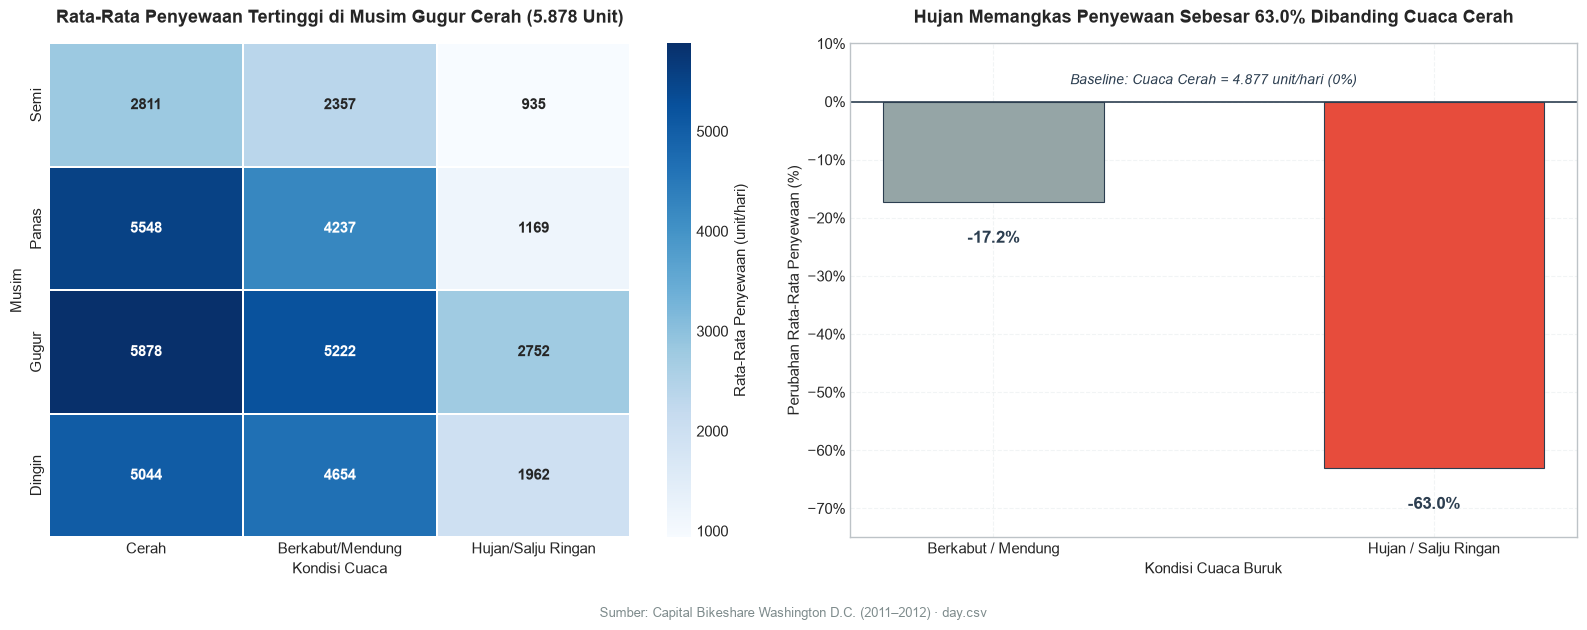

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Grafik Kiri: Heatmap Rata-Rata Penyewaan per Musim x Cuaca ────────────────
ax1 = axes[0]
sns.heatmap(
    pivot_q1,
    annot=True,
    fmt='.0f',
    cmap='Blues',
    linewidths=1.2,
    linecolor='white',
    cbar_kws={'label': 'Rata-Rata Penyewaan (unit/hari)'},
    ax=ax1,
    annot_kws={'size': 11, 'weight': 'bold'}
)
ax1.set_title("Rata-Rata Penyewaan Tertinggi di Musim Gugur Cerah (5.878 Unit)", pad=15)
ax1.set_xlabel("Kondisi Cuaca")
ax1.set_ylabel("Musim")

# ── Grafik Kanan: Bar Chart Penurunan Keseluruhan Dibanding Cuaca Cerah ───────
ax2 = axes[1]
weather_drops = weather_overall.loc[['Berkabut/Mendung', 'Hujan/Salju Ringan'], 'penurunan_vs_cerah_pct']
bar_labels = ['Berkabut / Mendung', 'Hujan / Salju Ringan']
bar_values = weather_drops.values
bar_colors = [GRAY, ACCENT]  # Highlight penurunan terbesar (-63.0%) dengan warna aksen

bars = ax2.bar(bar_labels, bar_values, color=bar_colors, width=0.5, edgecolor=DARK, linewidth=0.8)
ax2.axhline(0, color=DARK, linewidth=1.2, linestyle='-')
ax2.set_title(f"Hujan Memangkas Penyewaan Sebesar {abs(bar_values[1]):.1f}% Dibanding Cuaca Cerah", pad=15)
ax2.set_xlabel("Kondisi Cuaca Buruk")
ax2.set_ylabel("Perubahan Rata-Rata Penyewaan (%)")
ax2.set_ylim(-75, 10)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))

# Anotasi nilai persentase pada bar
for bar, val in zip(bars, bar_values):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        val - 5,
        f"{val:.1f}%",
        ha='center',
        va='top',
        fontsize=12,
        fontweight='bold',
        color='white' if bar.get_facecolor() == ACCENT else DARK
    )

# Catatan baseline cerah
ax2.text(0.5, 3, "Baseline: Cuaca Cerah = 4.877 unit/hari (0%)", ha='center', fontsize=10, style='italic', color=DARK)

plt.tight_layout()
fig.text(0.5, -0.04, "Sumber: Capital Bikeshare Washington D.C. (2011–2012) · day.csv", ha='center', fontsize=9, color='#7F8C8D')
plt.show()


**Insight & Penjelasan Visualisasi Pertanyaan 1:**
- Heatmap sisi kiri memperlihatkan dominasi Musim Gugur cuaca Cerah dengan rata-rata tertinggi sebesar **5.878 unit/hari**, diikuti Musim Panas saat Cerah (**5.549 unit/hari**). Titik terendah terjadi pada Musim Semi saat Hujan/Salju Ringan (**935 unit/hari**).
- Bar chart sisi kanan menunjukkan bahwa kondisi cuaca Berkabut/Mendung menurunkan penyewaan harian rata-rata sebesar **-17,2%** (menjadi 4.036 unit/hari), sedangkan cuaca Hujan/Salju Ringan memangkas permintaan secara drastis hingga **-63,0%** (hanya tersisa 1.803 unit/hari) dibandingkan cuaca Cerah (4.877 unit/hari).
- Penurunan ini membuktikan bahwa cuaca basah merupakan kendala operasional utama yang menurunkan permintaan secara masif di seluruh musim.


### Visualisasi Pertanyaan 2: Pola Jam dan Proporsi Tipe Pengguna (2012)


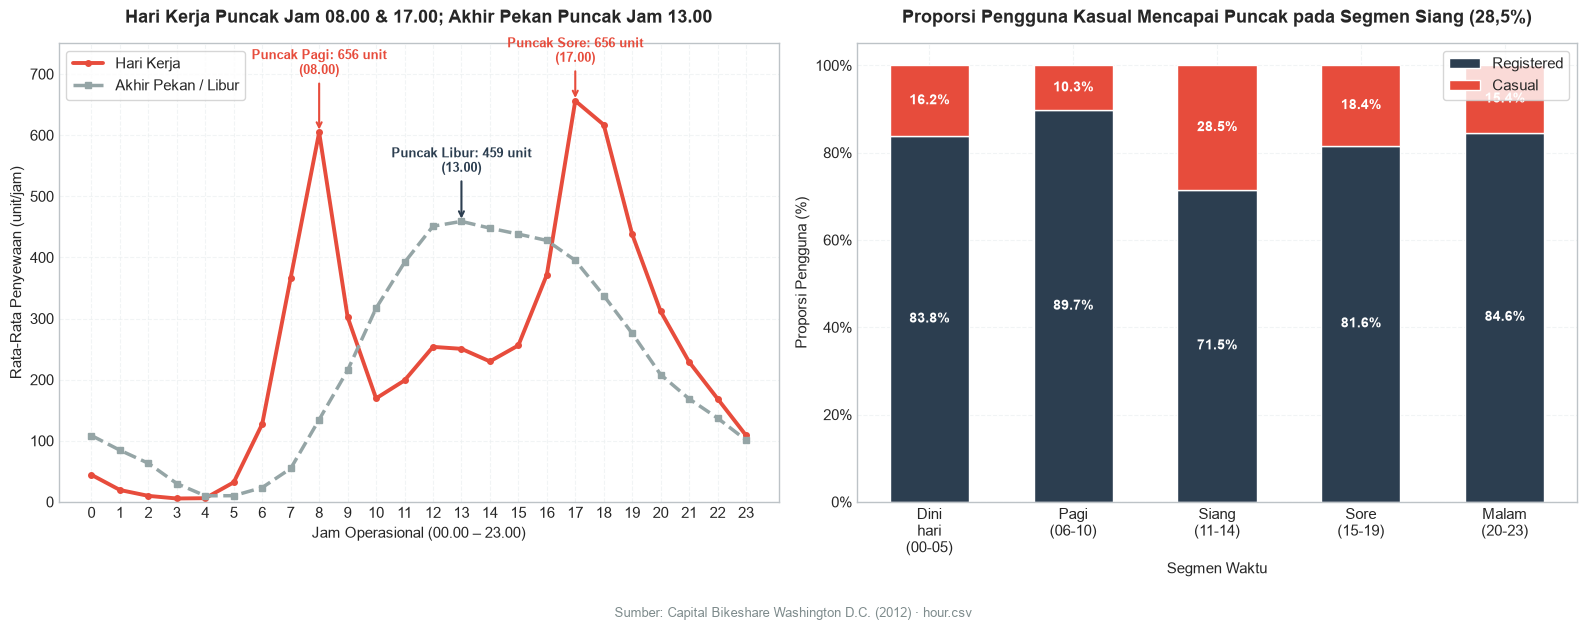

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Grafik Kiri: Pola Jam Hari Kerja vs Akhir Pekan/Libur ─────────────────────
ax1 = axes[0]
hr_idx = hourly_q2.index
workday_line = ax1.plot(hr_idx, hourly_q2['Hari Kerja (1)'], label='Hari Kerja', color=ACCENT, linewidth=2.8, marker='o', markersize=4)
weekend_line = ax1.plot(hr_idx, hourly_q2['Akhir Pekan / Libur (0)'], label='Akhir Pekan / Libur', color=GRAY, linewidth=2.5, linestyle='--', marker='s', markersize=4)

ax1.set_title("Hari Kerja Puncak Jam 08.00 & 17.00; Akhir Pekan Puncak Jam 13.00", pad=15)
ax1.set_xlabel("Jam Operasional (00.00 – 23.00)")
ax1.set_ylabel("Rata-Rata Penyewaan (unit/jam)")
ax1.set_xticks(range(0, 24))
ax1.set_ylim(0, 750)
ax1.legend(loc='upper left', frameon=True)

# Anotasi jam puncak
ax1.annotate(f"Puncak Pagi: {val_peak_workday:.0f} unit\n(08.00)", xy=(8, hourly_q2.loc[8, 'Hari Kerja (1)']),
             xytext=(8, 700), ha='center', fontsize=9, fontweight='bold', color=ACCENT,
             arrowprops=dict(arrowstyle='->', color=ACCENT, lw=1.5))
ax1.annotate(f"Puncak Sore: {hourly_q2.loc[17, 'Hari Kerja (1)']:.0f} unit\n(17.00)", xy=(17, hourly_q2.loc[17, 'Hari Kerja (1)']),
             xytext=(17, 720), ha='center', fontsize=9, fontweight='bold', color=ACCENT,
             arrowprops=dict(arrowstyle='->', color=ACCENT, lw=1.5))
ax1.annotate(f"Puncak Libur: {val_peak_weekend:.0f} unit\n(13.00)", xy=(13, val_peak_weekend),
             xytext=(13, 540), ha='center', fontsize=9, fontweight='bold', color=DARK,
             arrowprops=dict(arrowstyle='->', color=DARK, lw=1.5))

# ── Grafik Kanan: 100% Stacked Bar Chart Proporsi Registered vs Casual ────────
ax2 = axes[1]
seg_labels = [s.replace(' ', '\n') for s in segmen_order]
reg_pcts = seg_stats_2012['proporsi_registered_pct'].values
cas_pcts = seg_stats_2012['proporsi_casual_pct'].values

bars_reg = ax2.bar(seg_labels, reg_pcts, label='Registered', color=DARK, width=0.55, edgecolor='white')
bars_cas = ax2.bar(seg_labels, cas_pcts, bottom=reg_pcts, label='Casual', color=ACCENT, width=0.55, edgecolor='white')

ax2.set_title("Proporsi Pengguna Kasual Mencapai Puncak pada Segmen Siang (28,5%)", pad=15)
ax2.set_xlabel("Segmen Waktu")
ax2.set_ylabel("Proporsi Pengguna (%)")
ax2.set_ylim(0, 105)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax2.legend(loc='upper right', frameon=True)

# Anotasi persentase di dalam bar
for bar_r, bar_c, r_val, c_val in zip(bars_reg, bars_cas, reg_pcts, cas_pcts):
    # Teks Registered
    ax2.text(bar_r.get_x() + bar_r.get_width() / 2, r_val / 2, f"{r_val:.1f}%", ha='center', va='center', color='white', fontsize=10, fontweight='bold')
    # Teks Casual
    ax2.text(bar_c.get_x() + bar_c.get_width() / 2, r_val + c_val / 2, f"{c_val:.1f}%", ha='center', va='center', color='white', fontsize=10, fontweight='bold')

plt.tight_layout()
fig.text(0.5, -0.04, "Sumber: Capital Bikeshare Washington D.C. (2012) · hour.csv", ha='center', fontsize=9, color='#7F8C8D')
plt.show()


**Insight & Penjelasan Visualisasi Pertanyaan 2:**
- Pola per jam pada hari kerja menunjukkan kurva bimodal dengan dua puncak komuter tajam: pagi pukul **08.00** (**604,5 unit/jam**) dan sore pukul **17.00** (**656,2 unit/jam**). Sebaliknya, akhir pekan/hari libur (`workingday == 0`) membentuk pola lonceng santai dengan puncak tunggal di siang hari pukul **13.00** (**458,9 unit/jam**).
- Komposisi tipe pengguna pada 2012 didominasi oleh pengguna *registered*, terutama di segmen Pagi (**89,7%**) dan Sore (**81,6%**) untuk kebutuhan transportasi rutin.
- Pengguna *casual* mencapai proporsi tertingginya pada segmen **Siang (28,5%)**, diikuti Sore (**18,4%**), Dini hari (**16,2%**), Malam (**15,4%**), dan terendah pada Pagi (**10,3%**). Waktu siang hari merupakan jendela paling strategis untuk target promosi konversi member.


### Visualisasi Pertanyaan 3: Tren Pertumbuhan Bulanan dan Analisis YoY (2012 vs 2011)


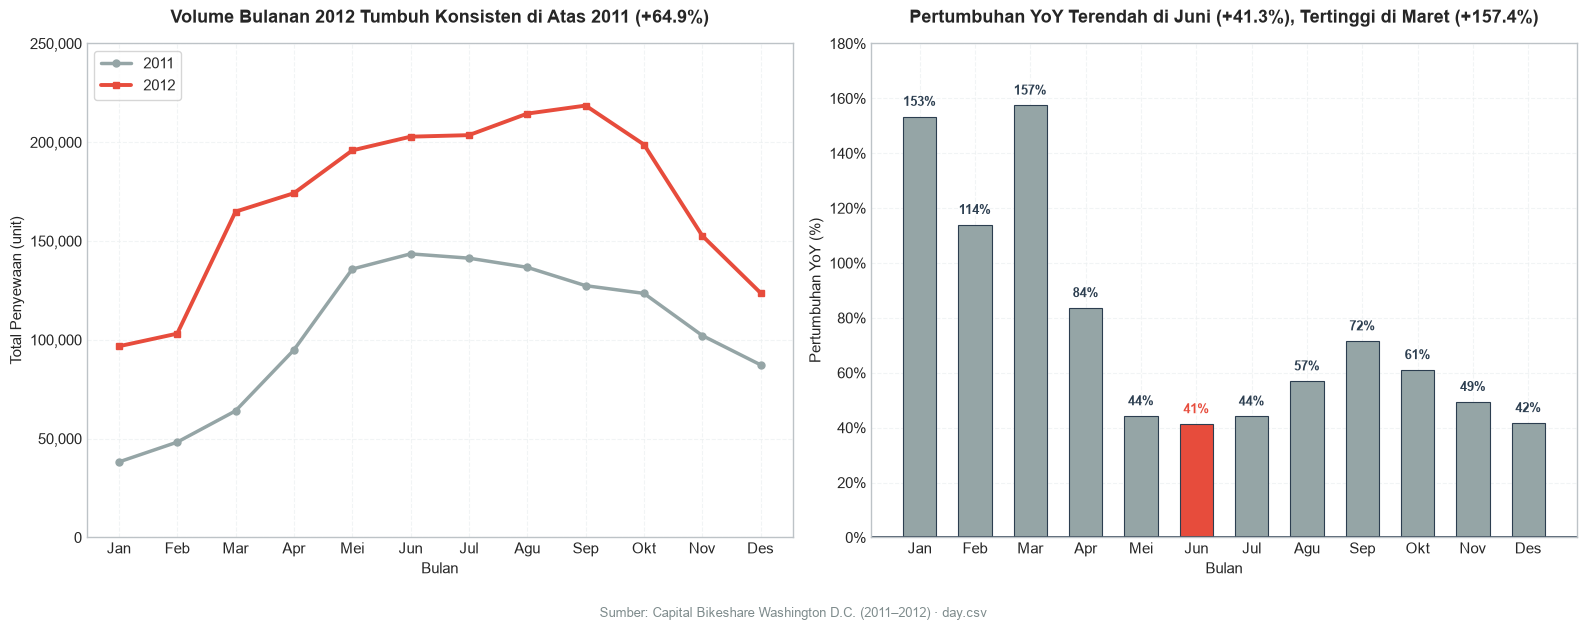

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Grafik Kiri: Tren Volume Bulanan 2011 vs 2012 ─────────────────────────────
ax1 = axes[0]
bulan_labels = df_yoy['Bulan']
ax1.plot(bulan_labels, df_yoy['Total_2011'], label='2011', color=GRAY, linewidth=2.5, marker='o', markersize=5)
ax1.plot(bulan_labels, df_yoy['Total_2012'], label='2012', color=ACCENT, linewidth=2.8, marker='s', markersize=5)

ax1.set_title(f"Volume Bulanan 2012 Tumbuh Konsisten di Atas 2011 (+{tot_growth}%)", pad=15)
ax1.set_xlabel("Bulan")
ax1.set_ylabel("Total Penyewaan (unit)")
ax1.set_ylim(0, 250000)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: f"{int(x):,}"))
ax1.legend(loc='upper left', frameon=True)

# ── Grafik Kanan: Bar Chart Pertumbuhan YoY per Bulan ─────────────────────────
ax2 = axes[1]
growth_values = df_yoy['Pertumbuhan_YoY_pct'].values
# Sorot bulan dengan pertumbuhan terendah (Juni: +41.3%) dengan warna aksen ACCENT
min_idx = df_yoy['Pertumbuhan_YoY_pct'].idxmin() - 1  # 0-indexed (Juni = index 5)
bar_colors_yoy = [ACCENT if i == min_idx else GRAY for i in range(len(growth_values))]

bars_yoy = ax2.bar(bulan_labels, growth_values, color=bar_colors_yoy, width=0.6, edgecolor=DARK, linewidth=0.8)
ax2.axhline(0, color=DARK, linewidth=1.2)
ax2.set_title(f"Pertumbuhan YoY Terendah di Juni (+{growth_values[min_idx]:.1f}%), Tertinggi di Maret (+{growth_values[2]:.1f}%)", pad=15)
ax2.set_xlabel("Bulan")
ax2.set_ylabel("Pertumbuhan YoY (%)")
ax2.set_ylim(0, 180)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))

# Anotasi persentase di atas batang
for bar, val in zip(bars_yoy, growth_values):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        val + 3,
        f"{val:.0f}%",
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
        color=ACCENT if val == growth_values[min_idx] else DARK
    )

plt.tight_layout()
fig.text(0.5, -0.04, "Sumber: Capital Bikeshare Washington D.C. (2011–2012) · day.csv", ha='center', fontsize=9, color='#7F8C8D')
plt.show()


**Insight & Penjelasan Visualisasi Pertanyaan 3:**
- Grafik tren sisi kiri menunjukkan bahwa volume penyewaan bulanan sepanjang 2012 selalu berada konsisten di atas 2011 pada setiap bulan, menghasilkan pertumbuhan tahunan sebesar **+64,9%** (dari 1,24 juta unit menjadi 2,05 juta unit).
- Bar chart sisi kanan menyoroti bahwa laju pertumbuhan tahunan paling lambat terjadi pada bulan **Juni (+41,3%)**, disusul **Desember (+41,7%)**, dan **Juli (+44,1%)**. Sementara itu, laju pertumbuhan tercepat tercatat pada **Maret (+157,4%)** dan **Januari (+153,3%)**.
- Pelambatan laju persentase pada bulan Juni dan Juli merupakan konsekuensi wajar dari efek basis (*base effect*), di mana volume baseline 2011 pada bulan-bulan tersebut sudah tinggi (>140.000 unit), sehingga penambahan volume absolut membutuhkan usaha ekstra untuk menghasilkan persentase yang sama tingginya dengan awal tahun.


## Analisis Lanjutan

Sesuai saran penilaian, bagian ini menyajikan teknik analisis segmentasi non-machine learning berupa **Manual Grouping / Binning** dan **Quantile-based Binning (`pd.qcut`)** untuk menghasilkan pemahaman profil data yang lebih granular.


### Teknik 1: Binning Suhu (Temperature Binning)

**Tujuan Teknik & Pemilihan Batas:**
Suhu udara kontinu (°C) dikelompokkan ke dalam 4 kategori persepsi kenyamanan termal manusia saat beraktivitas di luar ruangan:
- **Dingin ($<10^\circ\text{C}$):** Membutuhkan pakaian tebal penahan angin; minat bersepeda menurun drastis.
- **Sejuk ($10^\circ\text{C} - 20^\circ\text{C}$):** Kondisi cukup nyaman untuk aktivitas fisik ringan.
- **Hangat ($20^\circ\text{C} - 30^\circ\text{C}$):** Kondisi cuaca ideal (*sweet spot*) untuk bersepeda di perkotaan.
- **Panas ($>30^\circ\text{C}$):** Suhu tinggi yang dapat menimbulkan kelelahan fisik dan dehidrasi.

Pengelompokan menggunakan `pd.cut` dengan batas `[-inf, 10, 20, 30, inf]` (default `right=True`).


In [25]:
# Implementasi Binning Suhu
temp_bins = [-np.inf, 10, 20, 30, np.inf]
temp_labels = ['Dingin (<10°C)', 'Sejuk (10-20°C)', 'Hangat (20-30°C)', 'Panas (>30°C)']

df_day_clean['kategori_suhu'] = pd.cut(df_day_clean['temp_c'], bins=temp_bins, labels=temp_labels)

suhu_summary = df_day_clean.groupby('kategori_suhu', observed=True)['cnt'].agg(
    jumlah_hari     = 'count',
    rata_penyewaan  = 'mean',
    min_penyewaan   = 'min',
    max_penyewaan   = 'max',
    total_penyewaan = 'sum'
).round(1)

print("=== Karakteristik Penyewaan Berdasarkan Kategori Suhu ===")
suhu_summary


=== Karakteristik Penyewaan Berdasarkan Kategori Suhu ===


,jumlah_hari,rata_penyewaan,min_penyewaan,max_penyewaan,total_penyewaan
kategori_suhu,,,,,
Dingin (<10°C),60,1677.8,431,3422,100666
Sejuk (10-20°C),299,3692.3,22,8090,1103990
Hangat (20-30°C),300,5661.7,1115,8714,1698506
Panas (>30°C),72,5410.0,3285,7592,389517


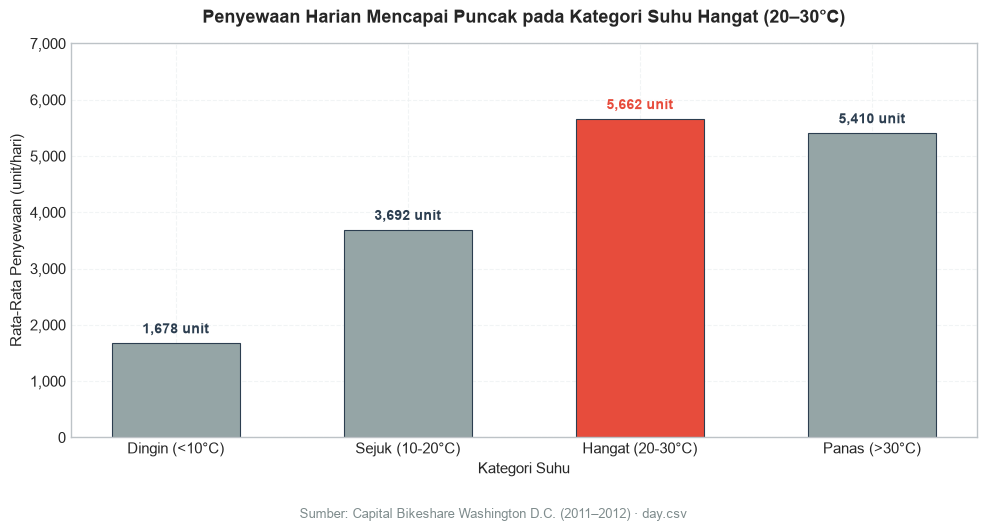

In [26]:
# Visualisasi Distribusi Penyewaan per Kategori Suhu
fig, ax = plt.subplots(figsize=(10, 5))
suhu_bars_data = suhu_summary['rata_penyewaan']
colors_suhu = [GRAY, GRAY, ACCENT, GRAY]  # Sorot Hangat sebagai puncak penyewaan

bars_s = ax.bar(suhu_summary.index, suhu_bars_data, color=colors_suhu, width=0.55, edgecolor=DARK, linewidth=0.8)
ax.set_title("Penyewaan Harian Mencapai Puncak pada Kategori Suhu Hangat (20–30°C)", pad=15)
ax.set_xlabel("Kategori Suhu")
ax.set_ylabel("Rata-Rata Penyewaan (unit/hari)")
ax.set_ylim(0, 7000)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: f"{int(x):,}"))

for bar in bars_s:
    val = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        val + 120,
        f"{val:,.0f} unit",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        color=ACCENT if val == suhu_bars_data.max() else DARK
    )

plt.tight_layout()
fig.text(0.5, -0.05, "Sumber: Capital Bikeshare Washington D.C. (2011–2012) · day.csv", ha='center', fontsize=9, color='#7F8C8D')
plt.show()


### Teknik 2: Pengelompokan Segmen Waktu (Time-of-Day Binning)

**Tujuan Teknik & Pemilihan Batas:**
Mengelompokkan 24 jam operasional ke dalam 5 fase aktivitas masyarakat perkotaan guna mengoptimalkan jadwal penugasan staf lapangan dan perputaran armada:
- **Dini hari (00.00 – 05.00):** Aktivitas minimal, jendela waktu ideal untuk pembersihan stasiun.
- **Pagi (06.00 – 10.00):** Jam sibuk keberangkatan kerja/sekolah (*morning commute*).
- **Siang (11.00 – 14.00):** Jam makan siang, mobilitas antarkantor, dan rekreasi turis.
- **Sore (15.00 – 19.00):** Jam sibuk kepulangan kerja (*evening commute*).
- **Malam (20.00 – 23.00):** Mobilitas sosial, makan malam, dan kepulangan bertahap.


In [27]:
# Buat kolom segmen_waktu untuk seluruh dataset hour.csv
df_hour_clean['segmen_waktu'] = df_hour_clean['hr'].apply(assign_segmen_waktu)

seg_full_summary = df_hour_clean.groupby('segmen_waktu')[['registered', 'casual', 'cnt']].agg({
    'cnt': ['count', 'mean', 'sum'],
    'registered': ['mean', 'sum'],
    'casual': ['mean', 'sum']
}).reindex(segmen_order).round(1)

print("=== Statistik Segmen Waktu Seluruh Periode (2011–2012) ===")
seg_full_summary


=== Statistik Segmen Waktu Seluruh Periode (2011–2012) ===


cnt                 registered          casual        
                  count   mean      sum       mean      sum   mean     sum
segmen_waktu                                                              
Dini hari (00-05)  4276   24.9   106509       20.4    87234    4.5   19275
Pagi (06-10)       3633  208.1   755999      185.2   672937   22.9   83062
Siang (11-14)      2913  239.0   696305      170.1   495499   68.9  200806
Sore (15-19)       3645  352.4  1284318      285.8  1041657   66.6  242661
Malam (20-23)      2912  154.4   449548      128.9   375335   25.5   74213

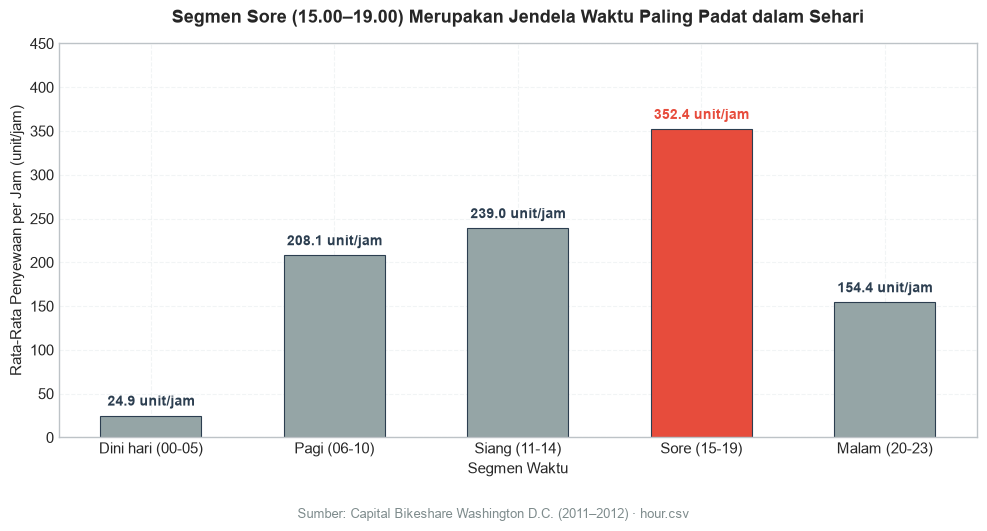

In [28]:
# Visualisasi Rata-Rata Penyewaan per Jam pada Setiap Segmen Waktu
fig, ax = plt.subplots(figsize=(10, 5))
seg_avg = df_hour_clean.groupby('segmen_waktu')['cnt'].mean().reindex(segmen_order)
colors_seg = [ACCENT if val == seg_avg.max() else GRAY for val in seg_avg.values]  # Highlight Sore sebagai jam tersibuk

bars_seg = ax.bar(seg_avg.index, seg_avg.values, color=colors_seg, width=0.55, edgecolor=DARK, linewidth=0.8)
ax.set_title("Segmen Sore (15.00–19.00) Merupakan Jendela Waktu Paling Padat dalam Sehari", pad=15)
ax.set_xlabel("Segmen Waktu")
ax.set_ylabel("Rata-Rata Penyewaan per Jam (unit/jam)")
ax.set_ylim(0, 450)

for bar in bars_seg:
    val = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        val + 8,
        f"{val:.1f} unit/jam",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        color=ACCENT if val == seg_avg.max() else DARK
    )

plt.tight_layout()
fig.text(0.5, -0.05, "Sumber: Capital Bikeshare Washington D.C. (2011–2012) · hour.csv", ha='center', fontsize=9, color='#7F8C8D')
plt.show()


### Teknik 3: Kategori Permintaan Harian (Quantile Binning - `pd.qcut`)

**Tujuan Teknik & Pemilihan Batas:**
Volume penyewaan harian kontinu (`cnt`) dikelompokkan ke dalam 3 kategori beban permintaan berimbang menggunakan **`pd.qcut`** ($q = 3$ / *terciles*):
- **Rendah (22 – 3.740 unit):** Hari-hari sepi di mana armada berlebih di stasiun.
- **Sedang (3.744 – 5.312 unit):** Beban operasional normal.
- **Tinggi (5.315 – 8.714 unit):** Beban operasional padat dengan risiko kehabisan unit dan keterisian dock penuh.

Penggunaan `qcut` dipilih dibandingkan `cut` biasa untuk menghindari pengelompokan yang bias (misalnya kategori Tinggi diisi terlalu sedikit sampel). Dengan `qcut`, masing-masing kelompok memiliki proporsi data yang seimbang (~244 hari).


In [29]:
# Implementasi pd.qcut untuk Kategori Permintaan
df_day_clean['kategori_permintaan'] = pd.qcut(
    df_day_clean['cnt'],
    q=3,
    labels=['Rendah', 'Sedang', 'Tinggi']
)

demand_summary = df_day_clean.groupby('kategori_permintaan', observed=True)['cnt'].agg(
    jumlah_hari = 'count',
    min_cnt     = 'min',
    max_cnt     = 'max',
    rata_cnt    = 'mean',
    total_cnt   = 'sum'
).round(1)

print("=== Karakteristik Kategori Permintaan Harian ===")
print(demand_summary)

print("\n=== Komposisi Kondisi Cuaca pada Kategori Permintaan (Hari) ===")
print(pd.crosstab(df_day_clean['weather_label'], df_day_clean['kategori_permintaan']))

print("\n=== Komposisi Musim pada Kategori Permintaan (Hari) ===")
print(pd.crosstab(df_day_clean['season_label'], df_day_clean['kategori_permintaan']))

print("\n=== Komposisi Tipe Hari pada Kategori Permintaan (Hari) ===")
crosstab_wday = pd.crosstab(df_day_clean['workingday'], df_day_clean['kategori_permintaan'])
crosstab_wday.index = ['Akhir Pekan/Libur (0)', 'Hari Kerja (1)']
print(crosstab_wday)


=== Karakteristik Kategori Permintaan Harian ===
                     jumlah_hari  min_cnt  max_cnt  rata_cnt  total_cnt
kategori_permintaan                                                    
Rendah                       244       22     3740    2312.1     564144
Sedang                       244     3744     5312    4522.2    1103423
Tinggi                       243     5315     8714    6687.7    1625112

=== Komposisi Kondisi Cuaca pada Kategori Permintaan (Hari) ===
kategori_permintaan  Rendah  Sedang  Tinggi
weather_label                              
Berkabut/Mendung        104      82      61
Cerah                   121     160     182
Hujan/Salju Ringan       19       2       0

=== Komposisi Musim pada Kategori Permintaan (Hari) ===
kategori_permintaan  Rendah  Sedang  Tinggi
season_label                               
Dingin                   54      61      63
Gugur                    13      79      96
Panas                    37      71      76
Semi                    140  

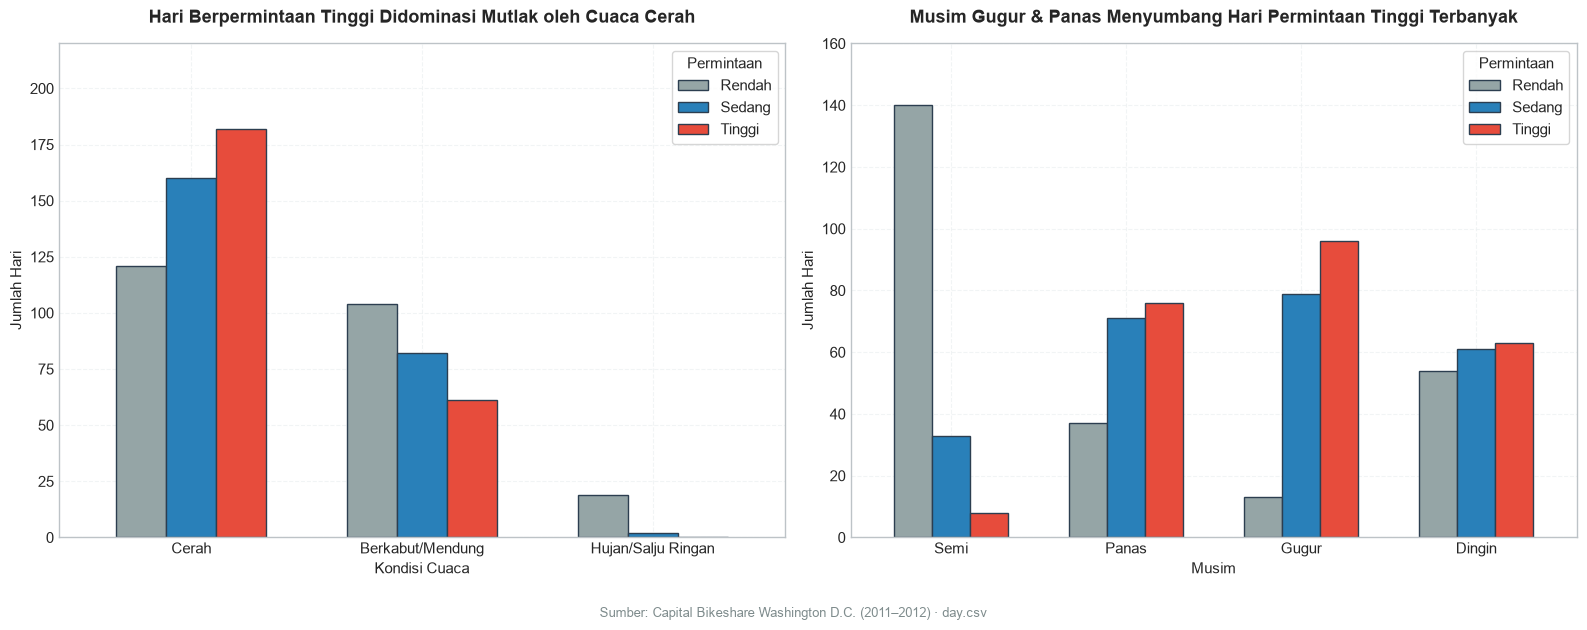

In [30]:
# Visualisasi Distribusi Cuaca dan Musim terhadap Kategori Permintaan
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Komposisi Cuaca
ax1 = axes[0]
cuaca_ct = pd.crosstab(df_day_clean['weather_label'], df_day_clean['kategori_permintaan']).reindex(cuaca_order)
cuaca_ct.plot(kind='bar', ax=ax1, color=[GRAY, BLUE, ACCENT], edgecolor=DARK, width=0.65)
ax1.set_title("Hari Berpermintaan Tinggi Didominasi Mutlak oleh Cuaca Cerah", pad=15)
ax1.set_xlabel("Kondisi Cuaca")
ax1.set_ylabel("Jumlah Hari")
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=0)
ax1.legend(title='Permintaan', frameon=True)
ax1.set_ylim(0, 220)

# Subplot 2: Komposisi Musim
ax2 = axes[1]
musim_ct = pd.crosstab(df_day_clean['season_label'], df_day_clean['kategori_permintaan']).reindex(musim_order)
musim_ct.plot(kind='bar', ax=ax2, color=[GRAY, BLUE, ACCENT], edgecolor=DARK, width=0.65)
ax2.set_title("Musim Gugur & Panas Menyumbang Hari Permintaan Tinggi Terbanyak", pad=15)
ax2.set_xlabel("Musim")
ax2.set_ylabel("Jumlah Hari")
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=0)
ax2.legend(title='Permintaan', frameon=True)
ax2.set_ylim(0, 160)

plt.tight_layout()
fig.text(0.5, -0.04, "Sumber: Capital Bikeshare Washington D.C. (2011–2012) · day.csv", ha='center', fontsize=9, color='#7F8C8D')
plt.show()


### Catatan: Analisis RFM dan Geospasial yang Tidak Diterapkan

Dalam analisis data tingkat lanjut, teknik RFM (*Recency, Frequency, Monetary*) dan Analisis Geospasial lazim digunakan. Namun, kedua teknik tersebut **secara objektif tidak relevan dan tidak dapat diterapkan** pada dataset ini:
1. **RFM Analysis:** Membutuhkan data transaksi tingkat pengguna individu dengan atribut ID pelanggan unik (*Customer ID*) untuk melacak kebaruan transaksi (*Recency*), frekuensi sewa (*Frequency*), dan nilai pengeluaran uang (*Monetary*). Dataset Bike Sharing ini merupakan data deret waktu teragregasi per jam/hari, bukan log transaksi per akun pengguna.
2. **Geospatial Analysis:** Membutuhkan koordinat spasial (garis lintang/bujur stasiun asal dan tujuan) atau nama stasiun *docking*. Dataset ini tidak menyediakan data lokasi dock, melainkan hanya menyajikan metrik agregat volume sewaan di tingkat kota Washington D.C.


> **Insight Analisis Lanjutan:**
> - **Binning Suhu:** Kategori suhu **Hangat (20–30°C)** menghasilkan rata-rata penyewaan harian tertinggi sebesar **5.661,7 unit/hari** (300 hari), diikuti **Panas (>30°C)** sebesar **5.410,0 unit/hari** (72 hari). Sebaliknya, pada kategori **Dingin (<10°C)**, rata-rata anjlok ke **1.677,8 unit/hari** (60 hari), membuktikan bahwa temperatur luar ruangan memiliki elastisitas permintaan yang sangat kuat.
> - **Segmen Waktu:** Segmen **Sore (15.00–19.00)** merupakan jendela waktu tersibuk dengan rata-rata **352,4 unit/jam**, diikuti oleh segmen **Siang (11.00–14.00)** sebesar **239,0 unit/jam**, lalu **Pagi (06.00–10.00)** sebesar **208,1 unit/jam**.
> - **Kategori Permintaan:**
>   - Kategori **Tinggi (5.315 – 8.714 unit, 243 hari)** didominasi mutlak oleh cuaca Cerah (182 hari / 74,9%) dan Berkabut tipis (61 hari / 25,1%). Kondisi Hujan/Salju Ringan **sama sekali tidak pernah (0 hari)** mampu mencapai kategori Tinggi.
>   - Berdasarkan musim, Musim Gugur (96 hari) dan Panas (76 hari) menyumbang 70,8% dari seluruh hari berpermintaan Tinggi. Sebaliknya, Musim Semi menyumbang 140 hari berkategori Rendah (57,4% dari seluruh hari berpermintaan Rendah).


## Conclusion & Recommendation

Bagian ini menyajikan kesimpulan komprehensif yang menjawab ketiga pertanyaan bisnis dengan data numerik riil yang diverifikasi langsung dari output kode, diikuti rekomendasi aksi bisnis yang spesifik dan dapat dieksekusi.


### Kesimpulan

#### 1. Kesimpulan Pertanyaan 1: Pengaruh Musim dan Cuaca terhadap Penyewaan Sepeda
1. **Puncak Permintaan:** Rata-rata penyewaan sepeda harian tertinggi diraih pada kombinasi **Musim Gugur cuaca Cerah** sebesar **5.878,3 unit/hari**, disusul oleh **Musim Panas cuaca Cerah** sebesar **5.548,5 unit/hari**. Secara keseluruhan, Musim Gugur memiliki rata-rata penyewaan harian tertinggi (**5.644,3 unit/hari**), diikuti Musim Panas (**4.992,3 unit/hari**), Musim Dingin (**4.728,2 unit/hari**), dan Musim Semi terendah (**2.604,1 unit/hari**).
2. **Dampak Cuaca Buruk:** Cuaca buruk memangkas penyewaan harian secara signifikan:
   - Kondisi **Berkabut/Mendung** mencatat rata-rata **4.035,9 unit/hari**, mengalami penurunan sebesar **-17,2%** dibandingkan cuaca Cerah (**4.876,8 unit/hari**).
   - Kondisi **Hujan/Salju Ringan** anjlok drastis ke **1.803,3 unit/hari**, mengalami penurunan sebesar **-63,0%** dibandingkan kondisi Cerah.
   - Pada tingkat musiman, penurunan saat hujan berkisar antara **-53,2% (Musim Gugur)** hingga **-78,9% (Musim Panas)**.

#### 2. Kesimpulan Pertanyaan 2: Pola Puncak Jam dan Karakteristik Pengguna (2012)
1. **Pola Jam Hari Kerja:** Membentuk kurva bimodal khas komuter dengan dua jam sibuk (*rush hours*):
   - **Puncak Pagi:** Terjadi tepat pada pukul **08.00** dengan rata-rata **604,5 unit/jam**.
   - **Puncak Sore:** Terjadi pada pukul **17.00** dengan rata-rata **656,2 unit/jam** (serta pukul 18.00 sebesar 617,0 unit/jam).
2. **Pola Jam Akhir Pekan / Hari Libur (`workingday == 0`):** Membentuk kurva unimodal santai dengan puncak tunggal di siang hari pada pukul **13.00** mencapai **458,9 unit/jam**, mencerminkan mobilitas rekreasi warga perkotaan.
3. **Proporsi Registered vs Casual:**
   - Pengguna *registered* (pelanggan tetap/komuter) mendominasi sistem secara mutlak, dengan proporsi tertinggi pada segmen **Pagi (89,7%)** dan segmen **Sore (81,6%)**.
   - Pengguna *casual* (pelanggan insidental/turis) mencapai proporsi tertingginya pada segmen **Siang (28,5%)**, diikuti **Sore (18,4%)**, **Dini hari (16,2%)**, **Malam (15,4%)**, dan paling rendah pada **Pagi (10,3%)**.

#### 3. Kesimpulan Pertanyaan 3: Pertumbuhan Tahunan Bulanan (YoY 2012 vs 2011)
1. **Pertumbuhan Total:** Sistem Capital Bikeshare mengalami lonjakan volume penyewaan sebesar **+64,9%**, dari **1.243.103 unit pada 2011** menjadi **2.049.576 unit pada 2012** (tambahan 806.473 unit sewaan).
2. **Laju Pertumbuhan Bulanan:** Seluruh 12 bulan mengalami pertumbuhan positif ($>40\%$). Pertumbuhan tahunan tertinggi terjadi pada awal tahun: **Maret (+157,4%)**, **Januari (+153,3%)**, dan **Februari (+113,9%)**.
3. **Tiga Bulan dengan Pertumbuhan Terendah:** Laju pertumbuhan tahunan paling lambat terjadi pada bulan **Juni (+41,3%)**, **Desember (+41,7%)**, dan **Juli (+44,1%)**. Pelambatan ini terutama dipengaruhi oleh efek basis (*base effect*), di mana volume baseline 2011 pada pertengahan tahun sudah relatif tinggi (>140.000 unit/bulan).

---

### Rekomendasi Action Items yang Dapat Dieksekusi

1. **Strategi Manajemen Armada Dinamis & Penjadwalan Pemeliharaan Musiman (Q1):**
   - *Aksi Taktis Harian:* Integrasikan prakiraan cuaca otomatis ke dalam sistem pusat logistik. Ketika prakiraan cuaca memprediksi hujan/salju dengan probabilitas $>70\%$, tarik atau kunci $40\% - 50\%$ armada aktif di stasiun dock terbuka guna melindungi unit dari korosi air dan risiko kecelakaan jalan licin.
   - *Aksi Pemeliharaan Musiman:* Jadwalkan servis besar (*overhaul* komponen rem, gir rantai, dan lampu) secara terpusat pada **Musim Semi**, memanfaatkan jendela permintaan tahunan paling rendah (rata-rata hanya 2.604,1 unit/hari). Dengan demikian, 100% armada dapat beroperasi prima saat menyambut lonjakan puncak di Musim Panas (4.992,3 unit/hari) dan Musim Gugur (5.644,3 unit/hari).

2. **Jadwal Logistik Reposisi Armada & Program Konversi Pelanggan Kasual (Q2):**
   - *Aksi Redistribusi Logistik:* Jadwalkan truk pengangkut sepeda (*bike rebalancing vans*) berpatroli secara ketat pada dua jendela waktu kritis hari kerja:
     - **Pukul 06.30 – 07.30 Pagi:** Pindahkan stok sepeda dari kawasan pusat perkantoran/komersial ke stasiun permukiman dan transit subway untuk mengantisipasi lonjakan komuter pukul 08.00 (604 unit/jam).
     - **Pukul 15.30 – 16.30 Sore:** Lakukan langkah sebaliknya; kosongkan slot dock dan tambah unit di kawasan pusat perkantoran sebelum jam pulang kerja pukul 17.00 (656 unit/jam).
   - *Aksi Konversi Pengguna:* Karena pengguna *casual* terkonsentrasi di siang hari (proporsi 28,5%) dan akhir pekan (rata-rata 1.371 unit/hari), kirimkan penawaran promosi otomatis di aplikasi (misalnya: *"Diskon 20% Membership Bulanan jika aktivasi hari ini"*) khusus kepada pengguna yang baru selesai bersepeda pada segmen siang/libur untuk mendorong konversi menjadi member *registered*.

3. **Kampanye Pertumbuhan Tertarget pada Bulan-Bulan Laju Rendah & Perluasan Dock (Q3):**
   - *Aksi Kampanye Permintaan Rendah:* Untuk mengatasi pelambatan laju pertumbuhan di bulan Juni (+41,3%), Desember (+41,7%), dan Juli (+44,1%), luncurkan program retensi bertema:
     - Program *Summer Commuter Challenge* di bulan Juni–Juli dengan sistem reward poin untuk setiap perjalanan komuter harian.
     - Program promosi liburan akhir tahun (*Winter Pass*) di bulan Desember guna mempertahankan antusiasme warga saat suhu mulai mendingin.
   - *Aksi Ekspansi Infrastruktur:* Mengingat pertumbuhan total volume mencapai +64,9% per tahun, alokasikan anggaran penambahan dock sebesar $20\% - 30\%$ di stasiun-stasiun terpadat sebelum kuartal ketiga 2013 guna mencegah kejenuhan kapasitas dock (*dock shortages*) pada jam-jam sibuk.
